In [1]:
import scanpy as sc
adata = sc.read_h5ad('data_bio/covid_portal.h5ad', backed='r')
print(adata)

AnnData object with n_obs × n_vars = 697612 × 31279 backed at 'data_bio/covid_portal.h5ad'
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'Resample', 'Collection_Day', 'Sex', 'Age', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'initial_clustering', 'full_clustering'
    var: 'feature_types'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'


In [12]:
print(adata.obs['initial_clustering'].value_counts())
print(adata.obs['full_clustering'].value_counts())

initial_clustering
CD14            146484
CD4             145592
CD8             102205
NK_16hi          85319
B_cell           66450
NK_56hi          29722
CD16             18041
Platelets        17017
Treg             16314
gdT              15753
Plasmablast      12243
MAIT              9026
DCs               7895
Lymph_prolif      7415
Doublet           5929
pDC               5173
HSC               3708
RBC               2614
Mono_prolif        712
Name: count, dtype: int64
full_clustering
NK_16hi                  83874
CD14_mono                75528
CD83_CD14_mono           69832
CD4.Naive                63141
CD8.TE                   53560
CD4.CM                   50022
B_naive                  43524
CD8.Naive                31256
NK_56hi                  26858
gdT                      20631
CD16_mono                19993
CD8.EM                   18974
CD4.IL22                 18409
Platelets                15073
CD4.Tfh                  13638
MAIT                     13432
B_swit

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

#X = adata.obsm['X_pca_harmony'].astype(np.float32)
#print(raw_labels)

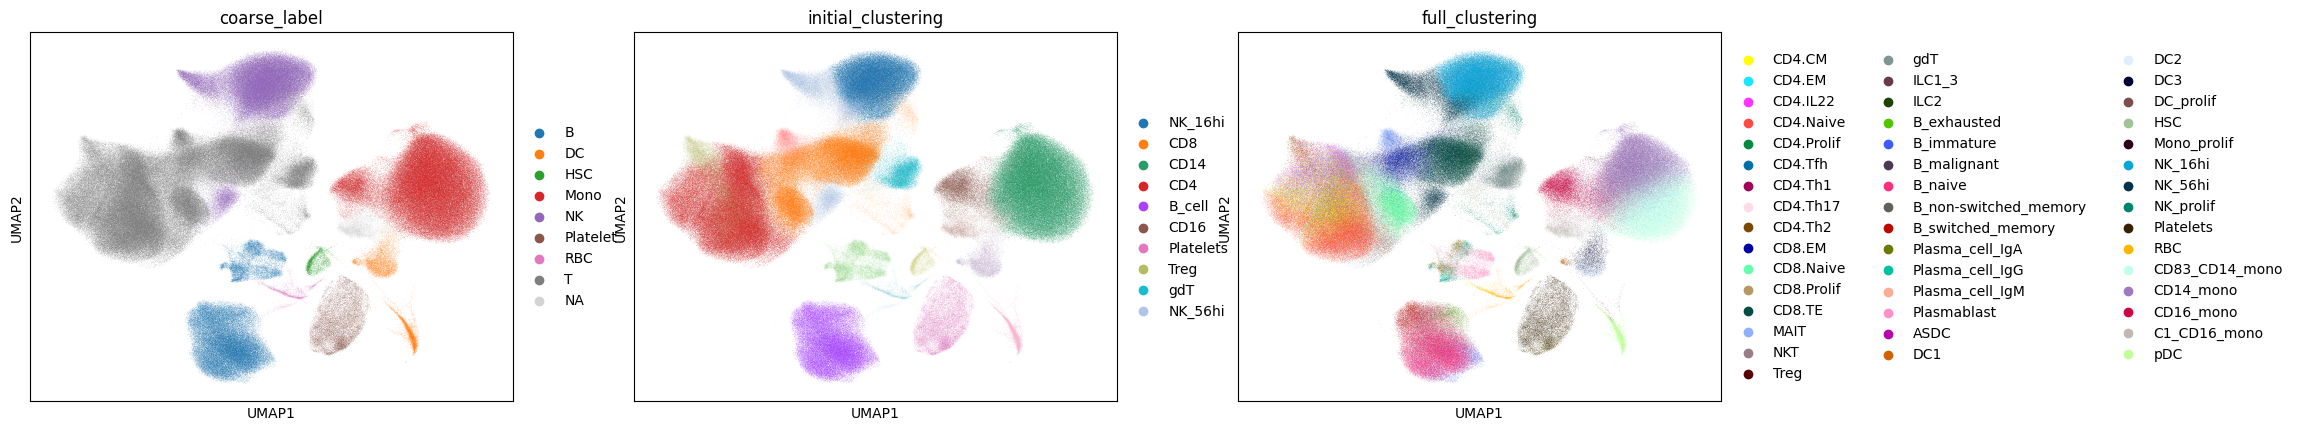

In [7]:
sc.pl.umap(adata, color = ['coarse_label', 'initial_clustering', 'full_clustering'])

In [13]:
latent_loader = DataLoader(TensorDataset(latents, labels), batch_size=256, shuffle= True)
BOTTLENECK = 20

class BridgeBuild(nn.Module):
    def __init__(self, input = 50, depth = 64, bottleneck = 20, centr = 1.0, rep = 0.0, do = 0.1):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(input, depth),
            nn.GELU(),
            nn.Dropout(do),
            nn.Linear(depth, bottleneck)
        )
        self.dec = nn.Sequential(
            nn.Linear(bottleneck, depth),
            nn.GELU(),
            nn.Dropout(do),
            nn.Linear(depth, input)
        )
        self.centroids = nn.Parameter(torch.randn(num_classes, bottleneck)) #рандом только ради инициализации, сразу перезаписывается
        self.mahalanobis = nn.Parameter(torch.eye(bottleneck), requires_grad = False) #I матрица заглушка
        
    def forward(self, x):
        h = self.enc(x)
        recon = self.dec(h)
        return h, recon
    
    def mahalanobis_distance(self, x, y):
        diff = x - y                                    # x_T * M * x
        return torch.sqrt(torch.clamp(torch.einsum("...i,ij,...j->...", diff, self.mahalanobis, diff), min = 1e-8))
    
BB = BridgeBuild(bottleneck = BOTTLENECK).to('cuda')
    

In [14]:
@torch.no_grad()
def refresh(model, latents, device):
    was_training = model.training
    model.eval()
    zs = model.enc(latents)
    centred = zs - zs.mean(dim=0)
    cov = (centred.T @ centred) / (centred.shape[0] - 1)
    eye = torch.eye(BOTTLENECK, device=device)
    model.mahalanobis.copy_(torch.linalg.pinv(cov + 1e-4 * eye))
    diff = model.centroids[:, None, :] - model.centroids[None, :, :]
    dists_sq = torch.einsum("ijk,kl,ijl->ij", diff, model.mahalanobis, diff)
    dists = torch.sqrt(torch.clamp(dists_sq, min=1e-8))
    mask = ~torch.eye(num_classes, dtype=torch.bool, device=device)
    if not hasattr(model, "margin"):
        model.register_buffer("margin", torch.tensor(0.0, device=device))
    model.margin.fill_(dists[mask].median().item() * 0.5)
    if was_training:
        model.train()

In [15]:
BB.eval()
with torch.no_grad():
    zs = BB.enc(latents)
    for c in range(num_classes):
        BB.centroids[c] = zs[labels == c].mean(dim = 0) #обычная инициализация средними
    
    centred = zs - zs.mean(dim = 0)
    cov = torch.cov(centred.T) # cov ждет в формате n_features, n_observations
    BB.mahalanobis.copy_(torch.linalg.pinv(cov + 1e-4 * torch.eye(BOTTLENECK, device = 'cuda')))
    diff = BB.centroids[:, None, :] - BB.centroids[None, :, :]
    dists_sq = torch.einsum("ijk,kl,ijl->ij", diff, BB.mahalanobis, diff)
    dists = torch.sqrt(torch.clamp(dists_sq, min=1e-8))
    mask = ~torch.eye(num_classes, dtype=torch.bool, device='cuda')
    median_dist = dists[mask].median().item()
    MARGIN = median_dist * 0.5
    print(f"MARGIN: {MARGIN:.4f}")
BB.train()
refresh(BB, latents, 'cuda')

MARGIN: 3.1868


In [16]:
lambda_cent = 0.1
lambda_rep = 0.01

def compute_loss(z, y, h, recon, cent):
    loss_recon = F.mse_loss(recon, z)
    diff_cent = h - cent[y]    # fancy indexing, соответствующий центроид отнимается у соответствующего h
    loss_cent = torch.einsum("bi,ij ,bj->b", diff_cent, BB.mahalanobis, diff_cent).mean()  # среднее со всех клеток батча
    diff = cent[:, None, :] - cent[None, :, :]
    dists_sq = torch.einsum("ijk,kl,ijl->ij", diff, BB.mahalanobis, diff)
    dists = torch.sqrt(torch.clamp(dists_sq, min=1e-8))
    mask = ~torch.eye(num_classes, dtype = torch.bool, device = 'cuda') # не расталкиваем матрицы сами с собой
    loss_rep = F.relu(BB.margin - dists[mask]).mean()
    return loss_recon + lambda_cent * loss_cent + lambda_rep * loss_rep

In [17]:
epochs = 10
optimizer = torch.optim.Adam(BB.parameters(), lr = 2e-3)

for epoch in range(epochs):
    BB.train()
    total, total_gn = 0.0, 0.0
    total_recon, total_cent, total_rep = 0.0, 0.0, 0.0
    total_cent_raw, total_rep_raw = 0.0, 0.0

    for z, y in latent_loader:
        z = z.to('cuda')
        y = y.to('cuda')

        h, recon = BB(z)
        loss = compute_loss(z, y, h, recon, BB.centroids)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(BB.parameters(), max_norm=50.0)
        optimizer.step()

        with torch.no_grad():
            recon_i = F.mse_loss(recon, z)
            diff_cent = h - BB.centroids[y]
            cent_i = torch.einsum("bi,ij,bj->b", diff_cent, BB.mahalanobis, diff_cent).mean()
            diff = BB.centroids[:, None, :] - BB.centroids[None, :, :]
            dists_sq = torch.einsum("ijk,kl,ijl->ij", diff, BB.mahalanobis, diff)
            dists = torch.sqrt(torch.clamp(dists_sq, min=1e-8))
            mask = ~torch.eye(num_classes, dtype=torch.bool, device='cuda')
            rep_i = F.relu(BB.margin - dists[mask]).mean()

        total += loss.item()
        total_gn += min(gn.item(), 1e6)
        total_recon += recon_i.item()
        total_cent  += cent_i.item()
        total_rep   += rep_i.item()
        total_cent_raw += (lambda_cent * cent_i).item()
        total_rep_raw  += (lambda_rep  * rep_i).item()

    refresh(BB, latents, 'cuda')

    n = len(latent_loader)
    print(f"Epoch {epoch+1:2d}/{epochs} | "
          f"loss={total/n:.4f} | gn={total_gn/n:.3f} | "
          f"recon={total_recon/n:.4f} | "
          f"cent={total_cent/n:.4f} (×{lambda_cent} → {total_cent_raw/n:.4f}) | "
          f"rep={total_rep/n:.4f} (×{lambda_rep} → {total_rep_raw/n:.4f}) | "
          f"margin={BB.margin.item():.4f}")

Epoch  1/10 | loss=1.2903 | gn=1.163 | recon=1.2022 | cent=0.8606 (×0.1 → 0.0861) | rep=0.1984 (×0.01 → 0.0020) | margin=3.9733
Epoch  2/10 | loss=1.1201 | gn=9.242 | recon=0.9501 | cent=1.6039 (×0.1 → 0.1604) | rep=0.3536 (×0.01 → 0.0035) | margin=4.0806
Epoch  3/10 | loss=1.0585 | gn=8.203 | recon=0.9283 | cent=1.2443 (×0.1 → 0.1244) | rep=0.2951 (×0.01 → 0.0030) | margin=4.4335
Epoch  4/10 | loss=1.0863 | gn=8.545 | recon=0.9507 | cent=1.2944 (×0.1 → 0.1294) | rep=0.3383 (×0.01 → 0.0034) | margin=3.6699
Epoch  5/10 | loss=1.0853 | gn=9.174 | recon=0.9585 | cent=1.2191 (×0.1 → 0.1219) | rep=0.2022 (×0.01 → 0.0020) | margin=3.4843
Epoch  6/10 | loss=1.0834 | gn=9.931 | recon=0.9603 | cent=1.1828 (×0.1 → 0.1183) | rep=0.1821 (×0.01 → 0.0018) | margin=3.0643
Epoch  7/10 | loss=1.0820 | gn=10.416 | recon=0.9617 | cent=1.1649 (×0.1 → 0.1165) | rep=0.1067 (×0.01 → 0.0011) | margin=2.5807
Epoch  8/10 | loss=1.0815 | gn=10.901 | recon=0.9633 | cent=1.1480 (×0.1 → 0.1148) | rep=0.0537 (×0.01 

In [ ]:
import numpy as np, gc, umap

rng = np.random.default_rng(0)
N_SUB = 120_000

def umap_via_subsample(X, tag, n_sub=N_SUB, n_neighbors=15, min_dist=0.3):
    X = X.astype(np.float32)
    idx = rng.choice(X.shape[0], size=n_sub, replace=False)
    reducer = umap.UMAP(
        n_neighbors=n_neighbors, min_dist=min_dist, n_components=2,
        metric='euclidean', random_state=0,
        low_memory=True, verbose=True,
    )
    reducer.fit(X[idx])
    emb = np.empty((X.shape[0], 2), dtype=np.float32)
    bs = 20_000
    for i in range(0, X.shape[0], bs):
        emb[i:i+bs] = reducer.transform(X[i:i+bs])
    np.save(f'umap_{tag}.npy', emb)
    del reducer; gc.collect()
    return emb

X_umap_harmony = adata.obsm['X_umap'].astype(np.float32)   
BB.eval()
with torch.no_grad():
    latent = BB.enc(latents).cpu().numpy().astype(np.float32)
print(f"bridge latent: {latent.shape}, dtype={latent.dtype}")
X_umap_bridge = umap_via_subsample(latent, 'bridge')